# Predicting Airline Passenger Satisfaction
### Kaggle Playground Series (Season 6, Episode 10)

This is a personal machine learning project where I analyze airline passenger survey data and build models to predict whether a passenger is satisfied or neutral/dissatisfied.

The project covers:
- Loading and exploring the dataset
- Visualizing satisfaction patterns across different passenger groups
- Cleaning missing values and encoding categorical features
- Comparing a linear baseline (Logistic Regression) with tree-based models (Decision Tree & LightGBM)
- Evaluating models using ROC-AUC (competition metric), Accuracy, and Confusion Matrix
- Checking feature importances to see which flight factors matter most
- Generating test predictions for submission


## 1. Importing Libraries
Importing standard data analysis and machine learning libraries.


In [1]:
# Core data processing libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn utilities and models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

# Plotting settings
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120


## 2. Loading the Dataset & Initial Checks
Reading both train and test datasets from the `data/` directory.


In [2]:
# Loading the datasets
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

print(f"Train dimensions: {train.shape[0]:,} rows, {train.shape[1]} columns")
print(f"Test dimensions:  {test.shape[0]:,} rows, {test.shape[1]} columns")


Train dimensions: 699,635 rows, 23 columns
Test dimensions:  299,844 rows, 22 columns


In [3]:
# Checking first few rows of train
train.head()


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [4]:
# Checking data types and memory usage
train.info()


<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

In [5]:
# Checking summary statistics for numeric features
train.describe().round(2)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.00,699635.0,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699343.00
mean,349817.00,39.0,1353.78,2.78,3.16,2.81,3.01,3.27,3.36,3.57,3.45,3.52,3.47,3.81,3.42,3.38,1.18,1.13
std,201967.37,13.8,954.42,1.28,1.48,1.33,1.25,1.30,1.29,1.28,1.31,1.24,1.27,1.08,1.21,1.28,5.98,5.75
min,0.00,7.0,67.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,174908.50,27.0,631.00,2.00,2.00,2.00,2.00,2.00,2.00,3.00,2.00,3.00,2.00,3.00,3.00,2.00,0.00,0.00
50%,349817.00,40.0,954.00,3.00,3.00,3.00,3.00,3.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,0.00,0.00
75%,524725.50,50.0,1814.00,4.00,4.00,4.00,4.00,4.00,4.00,5.00,5.00,4.00,5.00,5.00,4.00,4.00,0.00,0.00
max,699634.00,85.0,4983.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,489.00,491.00


In [6]:
# Checking missing values in train and test
print("Missing values in Train:")
print(train.isnull().sum()[train.isnull().sum() > 0])

print("\nMissing values in Test:")
print(test.isnull().sum()[test.isnull().sum() > 0])


Missing values in Train:
Arrival Delay in Minutes    292
dtype: int64

Missing values in Test:
Arrival Delay in Minutes    130
dtype: int64


## 3. Exploratory Data Analysis (EDA)
Here I visualize the distribution of the target variable and explore how different features relate to passenger satisfaction.


C:\Users\2335m\AppData\Local\Temp\ipykernel_28152\2863558580.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='satisfaction', data=train, palette=['#e74c3c', '#2ecc71'])


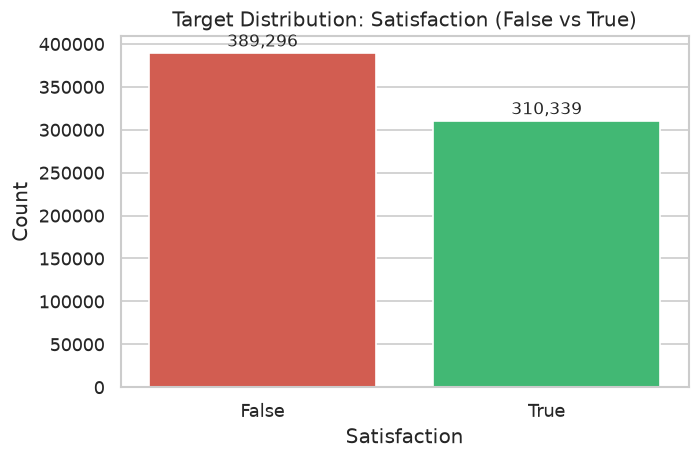

satisfaction
False    55.64
True     44.36
Name: proportion, dtype: float64


In [7]:
# Checking the distribution of the target variable 'satisfaction'
# I want to see if the classes are balanced or imbalanced
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='satisfaction', data=train, palette=['#e74c3c', '#2ecc71'])
plt.title('Target Distribution: Satisfaction (False vs True)', fontsize=12)
plt.xlabel('Satisfaction')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, xytext=(0, 4),
                textcoords='offset points')

plt.tight_layout()
plt.show()

# Proportion calculation
print(train['satisfaction'].value_counts(normalize=True).round(4) * 100)


C:\Users\2335m\AppData\Local\Temp\ipykernel_28152\1037950330.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x='Class', y=train['satisfaction'].astype(int), data=train, palette='Blues_d')


C:\Users\2335m\AppData\Local\Temp\ipykernel_28152\1037950330.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x='Type of Travel', y=train['satisfaction'].astype(int), data=train, palette='Purples_d')


C:\Users\2335m\AppData\Local\Temp\ipykernel_28152\1037950330.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[2], x='Customer Type', y=train['satisfaction'].astype(int), data=train, palette='Greens_d')


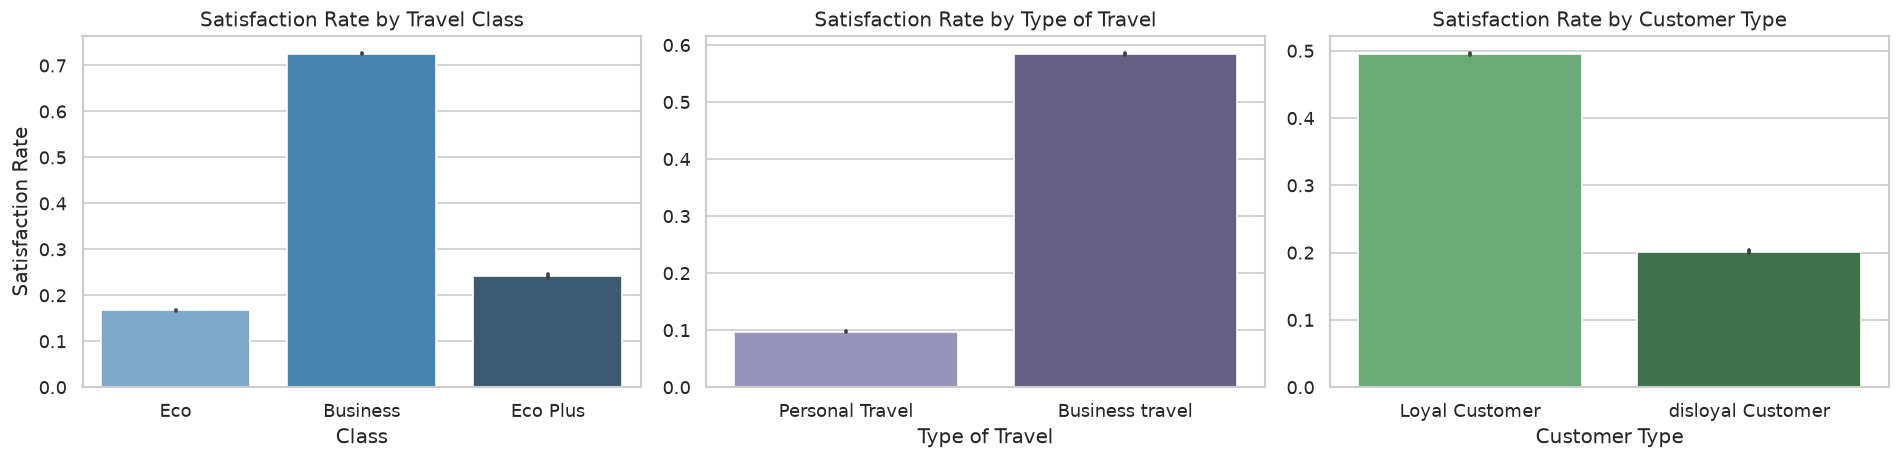

In [8]:
# Looking at satisfaction rates across Travel Class, Travel Type, and Customer Loyalty
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Travel Class
sns.barplot(ax=axes[0], x='Class', y=train['satisfaction'].astype(int), data=train, palette='Blues_d')
axes[0].set_title('Satisfaction Rate by Travel Class')
axes[0].set_ylabel('Satisfaction Rate')

# 2. Type of Travel
sns.barplot(ax=axes[1], x='Type of Travel', y=train['satisfaction'].astype(int), data=train, palette='Purples_d')
axes[1].set_title('Satisfaction Rate by Type of Travel')
axes[1].set_ylabel('')

# 3. Customer Type (Loyalty)
sns.barplot(ax=axes[2], x='Customer Type', y=train['satisfaction'].astype(int), data=train, palette='Greens_d')
axes[2].set_title('Satisfaction Rate by Customer Type')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()


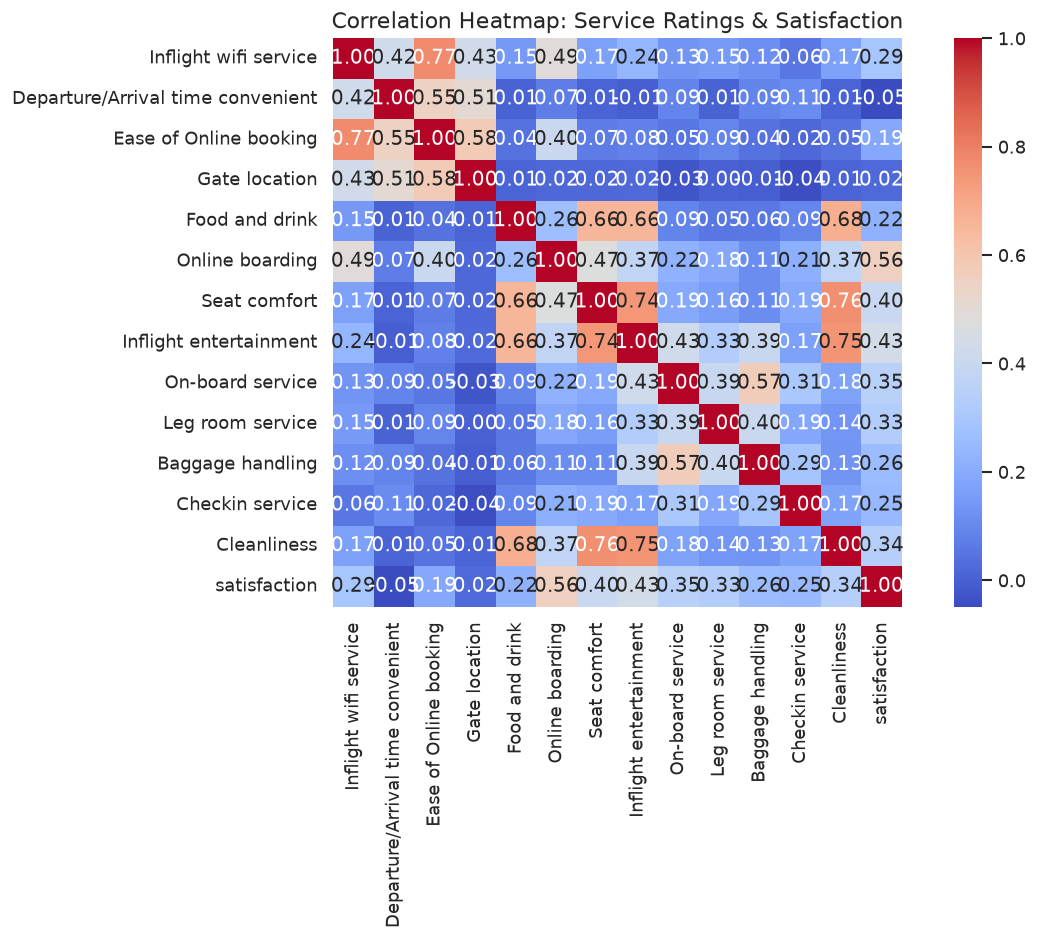

In [9]:
# Correlation heatmap for all the 0-5 rating features with satisfaction
rating_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

# Computing correlation with numeric satisfaction (0 or 1)
temp_df = train[rating_cols].copy()
temp_df['satisfaction'] = train['satisfaction'].astype(int)

plt.figure(figsize=(11, 8))
sns.heatmap(temp_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Heatmap: Service Ratings & Satisfaction', fontsize=13)
plt.tight_layout()
plt.show()


## 4. Data Preprocessing & Cleaning
In this step, I handle missing values, encode categorical variables, and prepare the feature matrix for modeling.


In [10]:
# Handling missing values in 'Arrival Delay in Minutes':
# Since arrival delay is closely tied to departure delay, I fill missing values with departure delay
train['Arrival Delay in Minutes'] = train['Arrival Delay in Minutes'].fillna(train['Departure Delay in Minutes'])
test['Arrival Delay in Minutes'] = test['Arrival Delay in Minutes'].fillna(test['Departure Delay in Minutes'])

# Converting target to integer: False -> 0, True -> 1
train['satisfaction'] = train['satisfaction'].astype(int)

# Mapping categorical variables to numbers
# Gender: Female -> 0, Male -> 1
# Customer Type: disloyal Customer -> 0, Loyal Customer -> 1
# Type of Travel: Personal Travel -> 0, Business travel -> 1
# Class: Eco -> 0, Eco Plus -> 1, Business -> 2 (ordinal order makes natural sense here)
gender_map = {'Female': 0, 'Male': 1}
cust_map = {'disloyal Customer': 0, 'Loyal Customer': 1}
travel_map = {'Personal Travel': 0, 'Business travel': 1}
class_map = {'Eco': 0, 'Eco Plus': 1, 'Business': 2}

for df in [train, test]:
    df['Gender'] = df['Gender'].map(gender_map)
    df['Customer Type'] = df['Customer Type'].map(cust_map)
    df['Type of Travel'] = df['Type of Travel'].map(travel_map)
    df['Class'] = df['Class'].map(class_map)

# Selecting features by dropping 'id' and 'satisfaction'
feature_cols = [col for col in train.columns if col not in ['id', 'satisfaction']]
X = train[feature_cols]
y = train['satisfaction']
X_test = test[feature_cols]
test_ids = test['id']

print("Features list:", feature_cols)


Features list: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class']


In [11]:
# Train-Validation split
# 80% train, 20% validation
# Using stratify=y so that the satisfaction proportion is equal in train and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_val shape:   {X_val.shape}")

# Scaling features for linear models like Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)


X_train shape: (559708, 21)
X_val shape:   (139927, 21)


## 5. Model Building & Validation
I train three models to observe how performance improves from a simple linear model to tree-based algorithms:
- **Logistic Regression**: Linear baseline model with standardized features.
- **Decision Tree**: Non-linear tree classifier with maximum depth limit to avoid overfitting.
- **LightGBM**: Fast gradient boosted decision trees, suited for tabular data.


In [12]:
# Model 1: Logistic Regression
print("Training Logistic Regression...")
lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train_scaled, y_train)

# Getting predicted probabilities for class 1
lr_val_probs = lr.predict_proba(X_val_scaled)[:, 1]
lr_val_preds = (lr_val_probs >= 0.5).astype(int)

lr_auc = roc_auc_score(y_val, lr_val_probs)
lr_acc = accuracy_score(y_val, lr_val_preds)
print(f"Logistic Regression -> ROC-AUC: {lr_auc:.4f} | Accuracy: {lr_acc:.4f}")


Training Logistic Regression...


Logistic Regression -> ROC-AUC: 0.9204 | Accuracy: 0.8779


In [13]:
# Model 2: Decision Tree Classifier
# Tree models don't require feature scaling and can capture non-linear decision boundaries
print("Training Decision Tree...")
dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train, y_train)

dt_val_probs = dt.predict_proba(X_val)[:, 1]
dt_val_preds = (dt_val_probs >= 0.5).astype(int)

dt_auc = roc_auc_score(y_val, dt_val_probs)
dt_acc = accuracy_score(y_val, dt_val_preds)
print(f"Decision Tree -> ROC-AUC: {dt_auc:.4f} | Accuracy: {dt_acc:.4f}")


Training Decision Tree...


Decision Tree -> ROC-AUC: 0.9500 | Accuracy: 0.9145


In [14]:
# Model 3: LightGBM Classifier
# Gradient boosting algorithm that builds trees sequentially to correct previous errors
print("Training LightGBM...")
lgb = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.08,
    random_state=42,
    verbose=-1
)
lgb.fit(X_train, y_train)

lgb_val_probs = lgb.predict_proba(X_val)[:, 1]
lgb_val_preds = (lgb_val_probs >= 0.5).astype(int)

lgb_auc = roc_auc_score(y_val, lgb_val_probs)
lgb_acc = accuracy_score(y_val, lgb_val_preds)
print(f"LightGBM -> ROC-AUC: {lgb_auc:.4f} | Accuracy: {lgb_acc:.4f}")


Training LightGBM...


LightGBM -> ROC-AUC: 0.9574 | Accuracy: 0.9241


## 6. Model Evaluation & Comparison
Comparing the validation results across all models.


In [15]:
# Summary table of validation performance
results_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'LightGBM'],
    'ROC-AUC': [lr_auc, dt_auc, lgb_auc],
    'Accuracy': [lr_acc, dt_acc, lgb_acc]
})
results_df.round(4)


,Model,ROC-AUC,Accuracy
0,Logistic Regression,0.9204,0.8779
1,Decision Tree,0.9500,0.9145
2,LightGBM,0.9574,0.9241


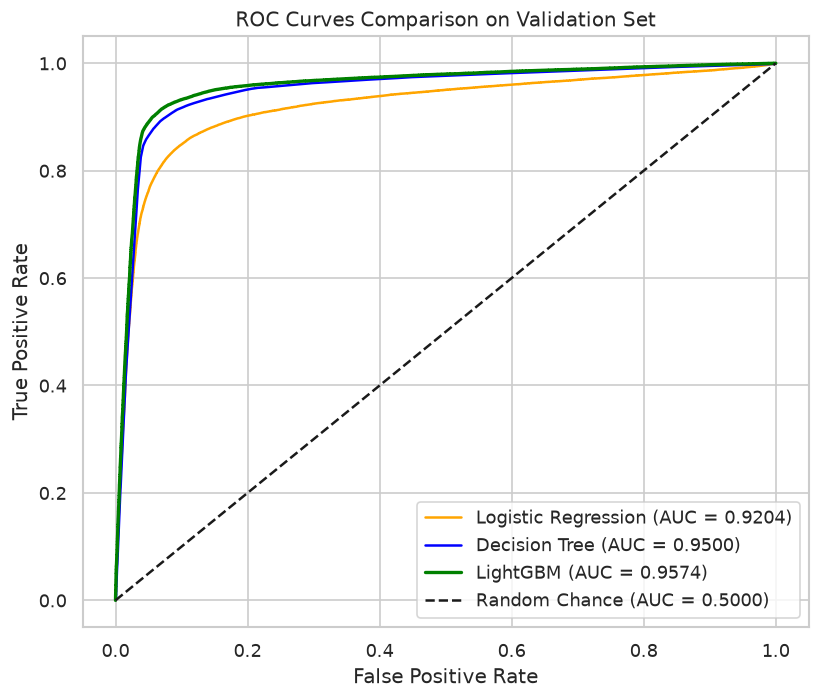

In [16]:
# Plotting ROC Curves for all three models
plt.figure(figsize=(7, 6))

fpr_lr, tpr_lr, _ = roc_curve(y_val, lr_val_probs)
fpr_dt, tpr_dt, _ = roc_curve(y_val, dt_val_probs)
fpr_lgb, tpr_lgb, _ = roc_curve(y_val, lgb_val_probs)

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_auc:.4f})', color='orange')
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {dt_auc:.4f})', color='blue')
plt.plot(fpr_lgb, tpr_lgb, label=f'LightGBM (AUC = {lgb_auc:.4f})', color='green', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.5000)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison on Validation Set')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [17]:
# Classification Report for the best model (LightGBM)
print("Classification Report (LightGBM):")
print(classification_report(y_val, lgb_val_preds, digits=4))


Classification Report (LightGBM):


              precision    recall  f1-score   support

           0     0.9228    0.9424    0.9325     77859
           1     0.9258    0.9011    0.9133     62068

    accuracy                         0.9241    139927
   macro avg     0.9243    0.9218    0.9229    139927
weighted avg     0.9241    0.9241    0.9240    139927



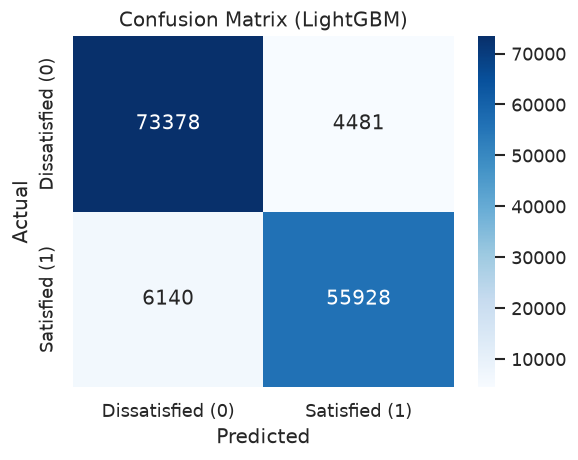

In [18]:
# Confusion Matrix for LightGBM
cm = confusion_matrix(y_val, lgb_val_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Dissatisfied (0)', 'Satisfied (1)'],
            yticklabels=['Dissatisfied (0)', 'Satisfied (1)'])
plt.title('Confusion Matrix (LightGBM)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


C:\Users\2335m\AppData\Local\Temp\ipykernel_28152\3176086122.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance.values, y=importance.index, palette='viridis')


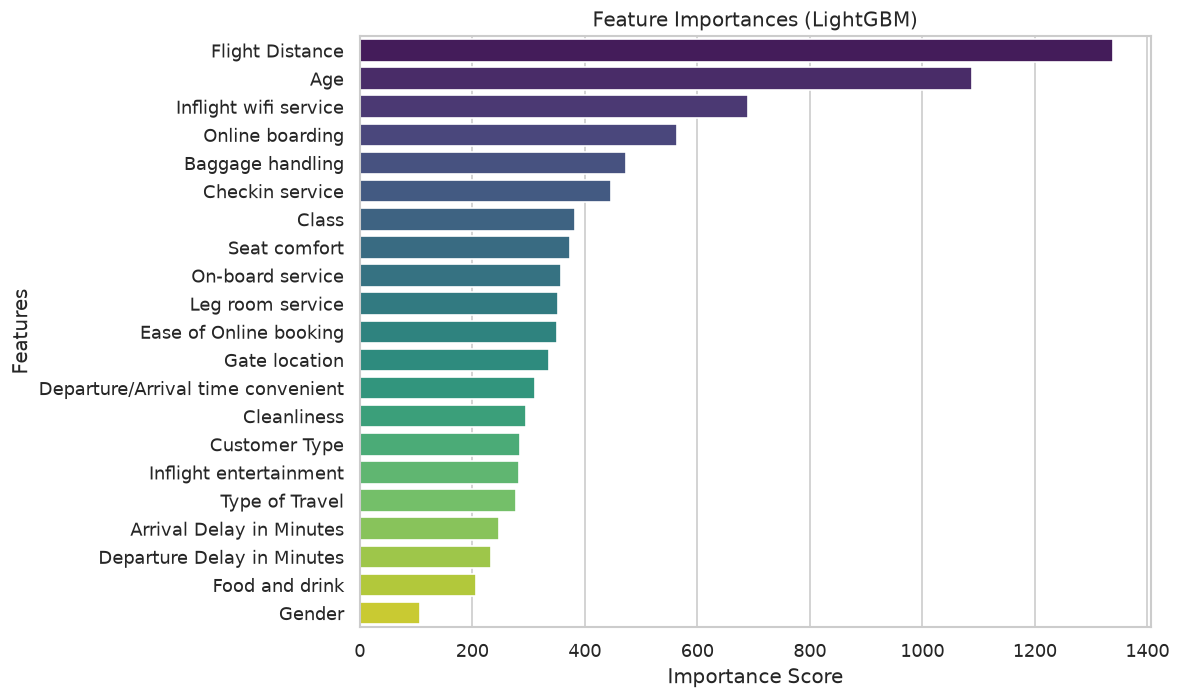

In [19]:
# Feature Importances from LightGBM
importance = pd.Series(lgb.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importance.values, y=importance.index, palette='viridis')
plt.title('Feature Importances (LightGBM)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


## 7. Generating Final Test Predictions
Now using the best-performing model (LightGBM) to predict probabilities for the test set and formatting the output as required by the competition (`id`, `satisfaction`).


In [20]:
# Predicting probabilities on the test set
test_probs = lgb.predict_proba(X_test)[:, 1]

# Building the submission dataframe
submission = pd.DataFrame({
    'id': test_ids,
    'satisfaction': test_probs
})

# Saving to CSV
submission.to_csv('../submission.csv', index=False)
print(f"Submission saved with {len(submission):,} rows.")
submission.head(10)


Submission saved with 299,844 rows.


,id,satisfaction
0,699635,0.178316
1,699636,0.885901
2,699637,0.918876
3,699638,0.063046
4,699639,0.040214
5,699640,0.962887
6,699641,0.032504
7,699642,0.931330
8,699643,0.973662
9,699644,0.032163


## 8. Summary & Key Learnings
- **Data Insights**: Online boarding, inflight entertainment, and wifi service are among the strongest drivers of airline customer satisfaction. Passengers traveling for business and flying business class have significantly higher satisfaction rates compared to personal travel or economy.
- **Model Progression**: Starting from a basic Logistic Regression baseline (0.9204 AUC), moving to a Decision Tree captured non-linear patterns (0.9500 AUC), and LightGBM achieved the highest performance (0.9574 AUC).
- **Practical Takeaway**: Proper preprocessing (handling missing values, ordinal encoding, and train-validation split stratification) provided a clean foundation for model comparison without requiring overly complex architectures.
